# 05 — Estudo de hiperparâmetros

Variação de um fator por vez, mapa de calor e random search — sempre na validação. O módulo `src/hparam_study.py` contém a implementação; esta notebook exibe os artefatos e só recalcula se ainda não existirem.

In [1]:
import sys
sys.path.append('..')
import pandas as pd
from IPython.display import Image, display
from src.config import REPORTS_DIR, FIGURES_DIR, TABLES_DIR
import src.hparam_study as hp
if not (REPORTS_DIR / 'models' / 'final_classificacao.json').exists():
    hp.main()
print('estudo disponível')

estudo disponível


## Tabela de sensibilidade (ordenada pelo impacto)

In [2]:
for nome in ['regressao', 'classificacao']:
    t = pd.read_csv(TABLES_DIR / f'05_sensibilidade_{nome}.csv')
    print('\n===', nome, '===')
    display(t.head(20))


=== regressao ===


,hiperparametro,valor,metrica_media,metrica_desvio,n_sementes,impacto
0,Otimizador,AdamW,9.588935,0.060019,3,15.231933
1,Otimizador,RMSprop,9.609292,0.064052,3,15.231933
2,Otimizador,SGD,24.820868,0.195656,3,15.231933
3,Otimizador,SGD_momentum,10.350391,0.086312,3,15.231933
4,Taxa de aprendizado,0.0001,17.155749,0.745797,3,7.566189
5,Taxa de aprendizado,0.01,9.589560,0.049908,3,7.566189
6,Taxa de aprendizado,0.1,10.294909,0.687846,3,7.566189
7,Dropout,0.1,9.541275,0.049862,3,0.741615
8,Dropout,0.3,9.582942,0.021579,3,0.741615
9,Dropout,0.5,10.282890,0.131925,3,0.741615



=== classificacao ===


,hiperparametro,valor,metrica_media,metrica_desvio,n_sementes,impacto
0,Otimizador,AdamW,0.782263,0.000430,3,0.526405
1,Otimizador,RMSprop,0.783799,0.005306,3,0.526405
2,Otimizador,SGD,0.257393,0.031486,3,0.526405
3,Otimizador,SGD_momentum,0.337770,0.086172,3,0.526405
4,Taxa de aprendizado,0.0001,0.441153,0.093426,3,0.338065
5,Taxa de aprendizado,0.01,0.766332,0.006058,3,0.338065
6,Taxa de aprendizado,0.1,0.779218,0.005174,3,0.338065
7,Tamanho do batch,32,0.783342,0.001941,3,0.051840
8,Tamanho do batch,512,0.731503,0.012760,3,0.051840
9,Tamanho do batch,8,0.781974,0.005432,3,0.051840


## Gráficos por hiperparâmetro e mapa de calor

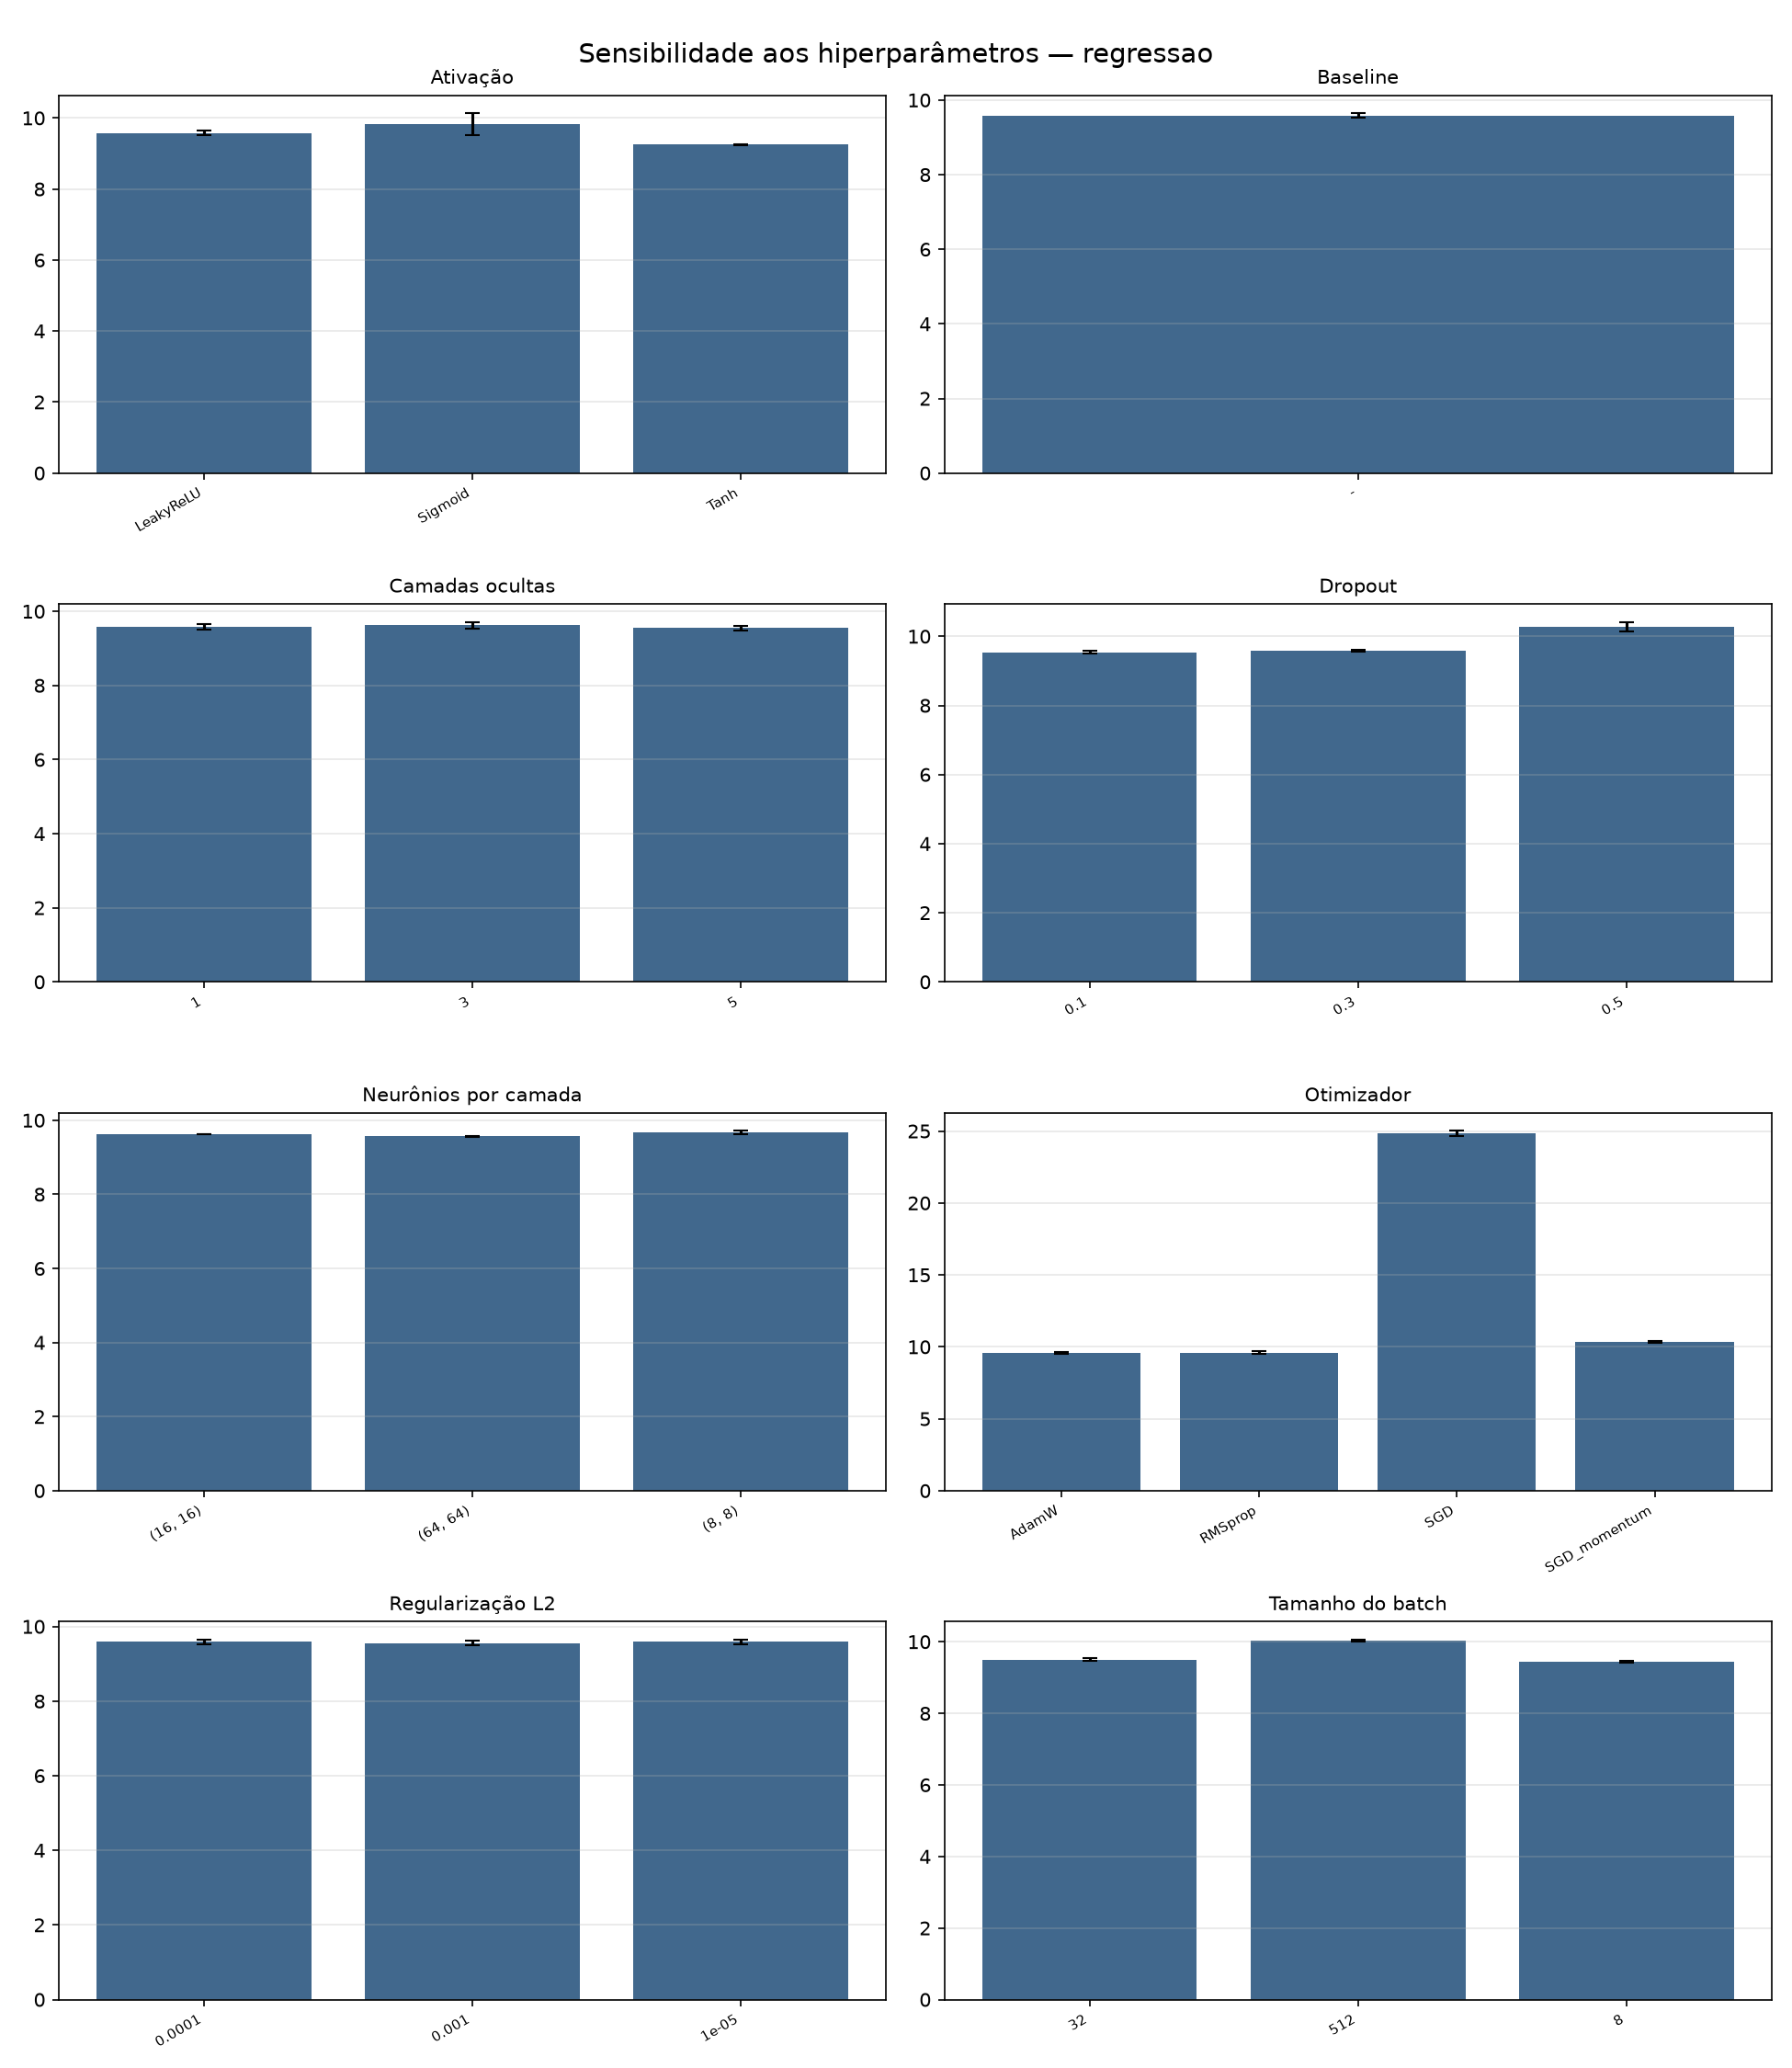

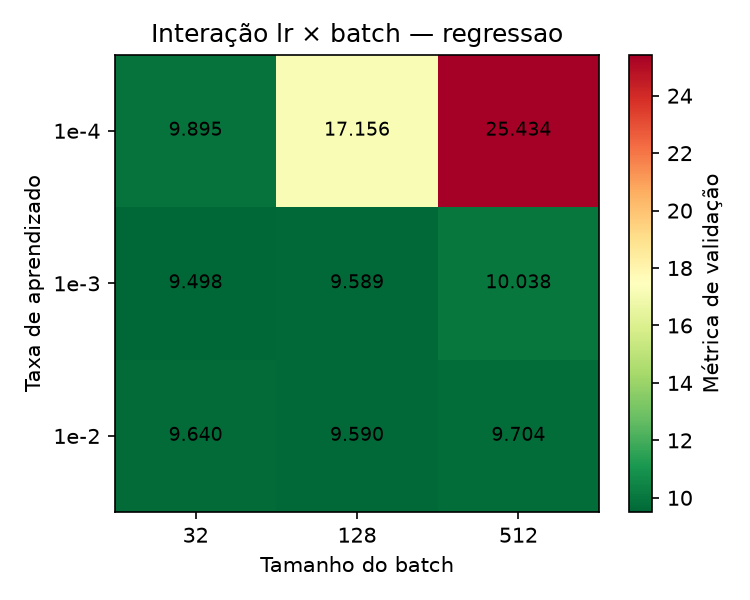

In [3]:
display(Image(filename=str(FIGURES_DIR / '05_hiperparametros_regressao.png')))
display(Image(filename=str(FIGURES_DIR / '05_mapa_calor_regressao.png')))

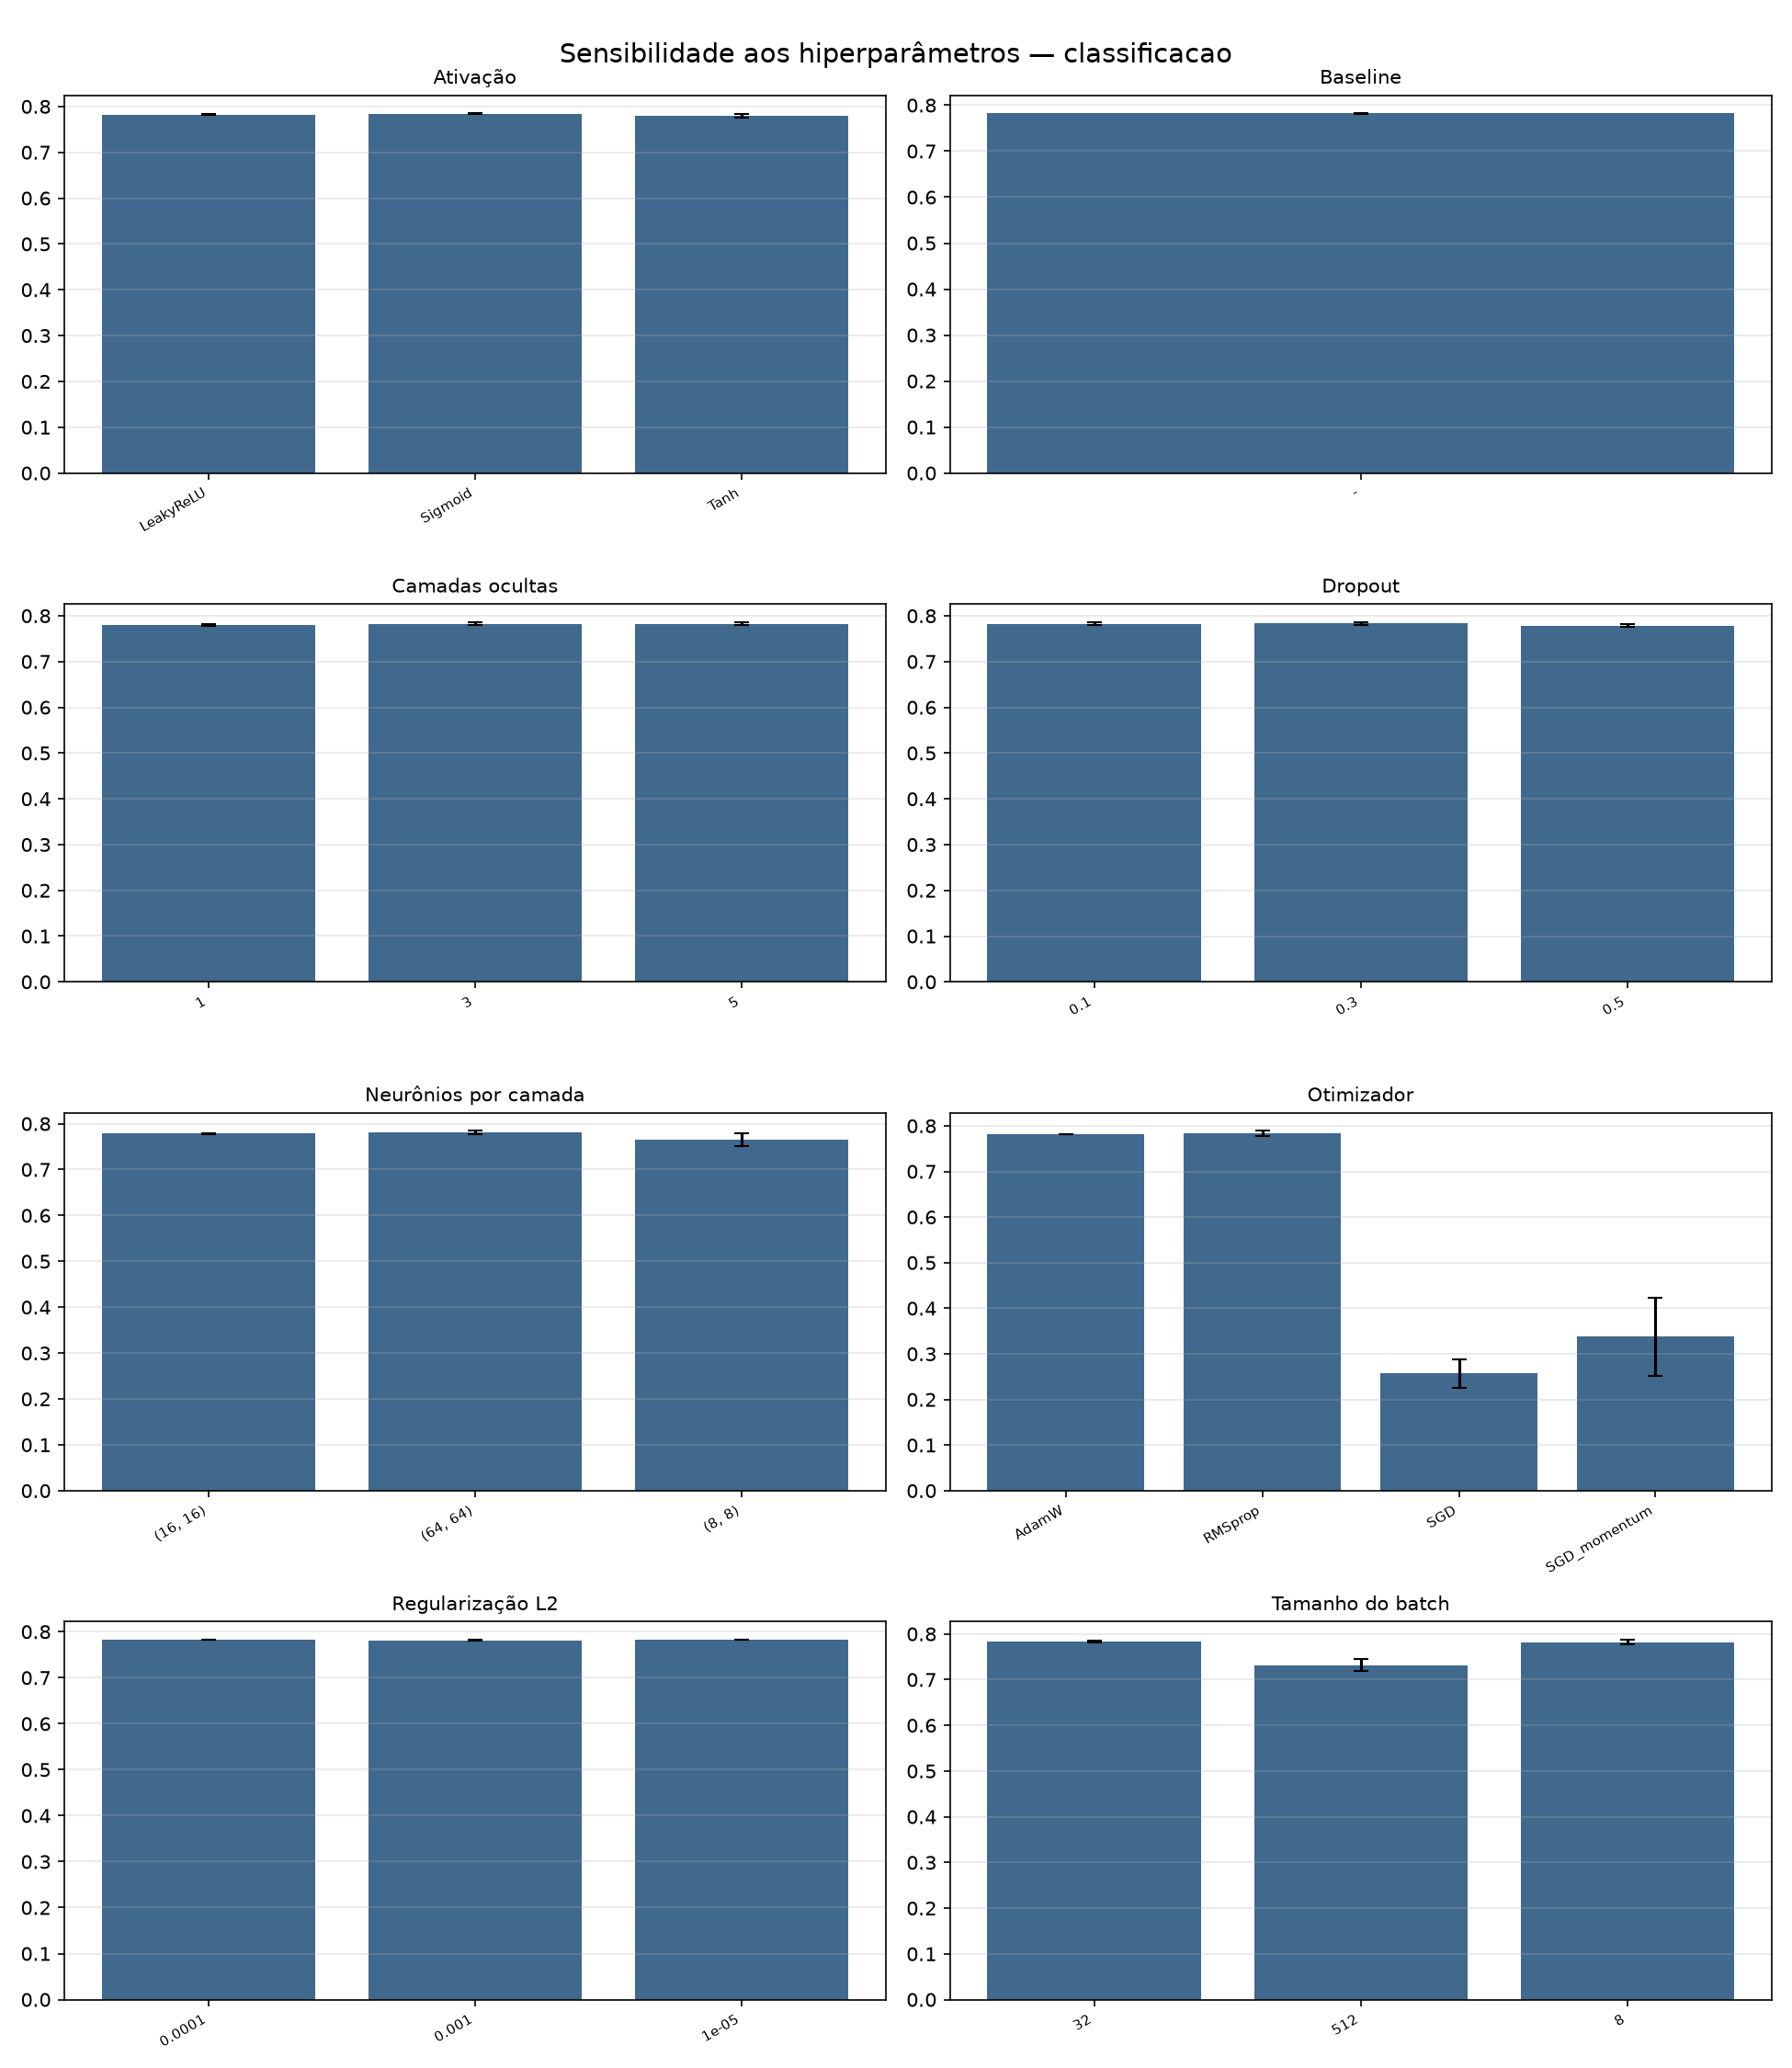

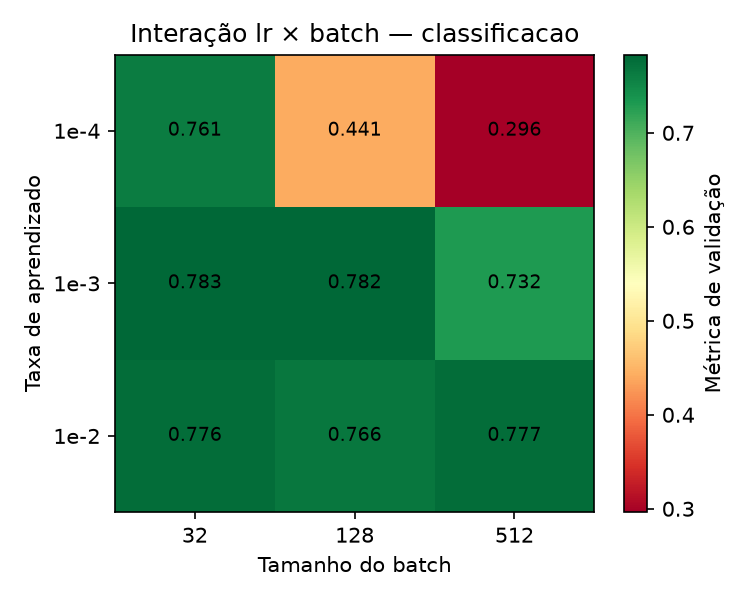

In [4]:
display(Image(filename=str(FIGURES_DIR / '05_hiperparametros_classificacao.png')))
display(Image(filename=str(FIGURES_DIR / '05_mapa_calor_classificacao.png')))

## Configurações finais escolhidas pela random search

In [5]:
for nome in ['regressao', 'classificacao']:
    cfg = pd.read_json(REPORTS_DIR / 'models' / f'config_final_{nome}.json', typ='series')
    print(nome, cfg.to_dict())

regressao {'hidden': [64, 64], 'activation': 'Tanh', 'optimizer': 'AdamW', 'lr': 0.0023809338343200002, 'batch_size': 256, 'dropout': 0.1, 'weight_decay': 0.0001, 'initialization': 'padrao', 'batch_norm': False}
classificacao {'hidden': [16, 16, 16], 'activation': 'LeakyReLU', 'optimizer': 'AdamW', 'lr': 0.001292346937795, 'batch_size': 32, 'dropout': 0.1, 'weight_decay': 0.001, 'initialization': 'padrao', 'batch_norm': False}
